# Chapter 4 Math Check — Coffee Bean Defect Classification

This notebook re-derives the tables in Chapter 4 directly from `results_full.csv`
so each printed number can be checked against a clearly-stated selection rule.

**How to use this notebook:**
1. Run the setup cell.
2. For each table, run the cell(s) and compare the printed output to the value in the thesis.
3. Where a table's method is ambiguous (e.g. "best-tuned configuration"), multiple
   candidate methods are computed side-by-side so you can see which one the
   printed numbers actually match, and pick the one you intend to report.


In [3]:
import pandas as pd
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

df = pd.read_csv('results_full_v2.csv')  # update path if needed
print(df.shape)
df.head()


(120, 36)


,folder_name,run_name,phase,train_variety,model,optimizer,lr,batch_size,dropout,max_epochs,...,macro_avg__precision,macro_avg__recall,macro_avg__f1-score,macro_avg__support,weighted_avg__precision,weighted_avg__recall,weighted_avg__f1-score,weighted_avg__support,accuracy,confusion_matrix
0,fixed_NORLR_arabica_efficientnet_adam_lr1e-4_b...,fixed_NORLR_arabica_efficientnet_adam_lr1e-4_b...,stage1,arabica,efficientnet,adam,0.0001,16,0.2000,100,...,0.9405,0.9493,0.9446,215.0000,0.9497,0.9488,0.9491,215.0000,0.9488,"[[94, 4, 1], [1, 70, 3], [1, 1, 40]]"
1,fixed_NORLR_arabica_efficientnet_adam_lr1e-4_b...,fixed_NORLR_arabica_efficientnet_adam_lr1e-4_b...,stage1,arabica,efficientnet,adam,0.0001,16,0.2000,100,...,0.8737,0.8654,0.8684,177.0000,0.9045,0.9040,0.9028,177.0000,0.9040,"[[67, 6, 4], [0, 76, 1], [4, 2, 17]]"
2,fixed_NORLR_arabica_efficientnet_adamw_lr1e-4_...,fixed_NORLR_arabica_efficientnet_adamw_lr1e-4_...,stage1,arabica,efficientnet,adamw,0.0001,16,0.2000,100,...,0.9365,0.9413,0.9388,215.0000,0.9446,0.9442,0.9443,215.0000,0.9442,"[[94, 4, 1], [1, 70, 3], [2, 1, 39]]"
3,fixed_NORLR_arabica_efficientnet_adamw_lr1e-4_...,fixed_NORLR_arabica_efficientnet_adamw_lr1e-4_...,stage1,arabica,efficientnet,adamw,0.0001,16,0.2000,100,...,0.8864,0.8698,0.8762,177.0000,0.9098,0.9096,0.9078,177.0000,0.9096,"[[67, 6, 4], [0, 77, 0], [4, 2, 17]]"
4,fixed_NORLR_arabica_efficientnet_adan_lr1e-4_b...,fixed_NORLR_arabica_efficientnet_adan_lr1e-4_b...,stage1,arabica,efficientnet,adan,0.0001,16,0.2000,100,...,0.9527,0.9605,0.9564,215.0000,0.9635,0.9628,0.9630,215.0000,0.9628,"[[96, 2, 1], [0, 71, 3], [1, 1, 40]]"


## Reference: dataset structure

- `phase`: `phase12` (Stage 1/2 hyperparameter sweep) or `phase3` (cross-variety fine-tuning)
- `train_variety`: variety the model was (finally) trained on
- `test_variety`: `same` (same-variety test set) or `other` (opposite-variety, zero-shot)
- `best_val_loss`: validation loss at the selected checkpoint — this is what early
  stopping/model selection was actually based on, so it's the right criterion for
  picking a "best" config without peeking at test performance.


In [3]:
d12_same = df[(df.phase == 'phase12') & (df.test_variety == 'same')].copy()
d3_same  = df[(df.phase == 'phase3')  & (df.test_variety == 'same')].copy()

print('phase12, same-variety rows:', len(d12_same))
print('phase3,  same-variety rows:', len(d3_same))


phase12, same-variety rows: 400
phase3,  same-variety rows: 50


---
## Table 4.3.1 — Mean Optimizer Performance (Phases 1–2, Same-Variety)

**Printed in thesis:**

| Optimizer | Mean Acc | Mean Prec | Mean Macro F1 | Std Dev (F1) |
|---|---|---|---|---|
| RMSProp | 95.22% | 94.46% | 94.45% | 0.0319 |
| Adam | 94.31% | 93.55% | 93.49% | 0.0480 |
| AdamW | 93.83% | 93.05% | 92.96% | 0.0510 |
| Adan | 92.60% | 92.24% | 91.53% | 0.0963 |
| SGD | 77.68% | 76.87% | 74.02% | 0.2028 |

Caption claims: *"each optimizer's best-tuned configuration per model and variety"* (n=10/optimizer).

Below: three candidate methods. Compare each to the table above.


In [7]:
def summarize(sub, group_col='optimizer'):
    g = sub.groupby(group_col)
    out = g.agg(
        n=('macro_avg__f1-score', 'size'),
        mean_acc=('accuracy', 'mean'),
        mean_prec=('macro_avg__precision', 'mean'),
        mean_f1=('macro_avg__f1-score', 'mean'),
        std_f1=('macro_avg__f1-score', 'std'),
    )
    
    # Convert performance metrics to percentages and round to 2 decimal places
    for col in ['mean_acc', 'mean_prec', 'mean_f1']:
        out[col] = (out[col] * 100).round(2)

    # Keep standard deviation as a decimal, rounded to 4 decimal places
    out['std_f1'] = out['std_f1'].round(4)

    return out.sort_values('mean_f1', ascending=False)


# Method A: mean across ALL phase1/2 configs per optimizer (no selection at all)
method_a = summarize(d12_same)
print('Method A: mean over ALL configs per optimizer')
print(method_a, '\n')

# Method B: best-of-group selected by TEST macro F1 (test-set peeking — not recommended,
# shown only for comparison)
best_by_test = d12_same.loc[
    d12_same.groupby(['optimizer', 'model', 'train_variety'])['macro_avg__f1-score'].idxmax()
]
method_b = summarize(best_by_test)
print('Method B: best-of-10 selected by TEST macro F1 (leaky, for comparison only)')
print(method_b, '\n')

# Method C: best-of-group selected by VALIDATION LOSS (no test-set peeking — recommended)
best_by_val = d12_same.loc[
    d12_same.groupby(['optimizer', 'model', 'train_variety'])['best_val_loss'].idxmin()
]
method_c = summarize(best_by_val)
print('Method C: best-of-10 selected by VALIDATION LOSS (recommended)')
print(method_c)


Method A: mean over ALL configs per optimizer
            n  mean_acc  mean_prec  mean_f1  std_f1
optimizer                                          
rmsprop    80   95.2200    94.4600  94.4500  0.0321
adam       80   94.3100    93.5500  93.4900  0.0483
adamw      80   93.8300    93.0500  92.9600  0.0513
adan       80   92.6000    92.2400  91.5300  0.0969
sgd        80   77.6800    76.8700  74.0200  0.2041 

Method B: best-of-10 selected by TEST macro F1 (leaky, for comparison only)
            n  mean_acc  mean_prec  mean_f1  std_f1
optimizer                                          
rmsprop    10   97.2900    97.1300  96.9800  0.0203
adam       10   97.1400    96.4500  96.7200  0.0190
adamw      10   96.7000    96.1600  96.2400  0.0256
adan       10   96.5000    95.7700  96.0100  0.0198
sgd        10   87.9300    87.8900  85.2300  0.0792 

Method C: best-of-10 selected by VALIDATION LOSS (recommended)
            n  mean_acc  mean_prec  mean_f1  std_f1
optimizer                      

**Notes / to decide:**
- Method A reproduces the printed table almost exactly — meaning the current table is
  actually an all-configs mean, not a best-tuned selection as the caption states.
- Method C is the methodologically correct "best-tuned configuration" (selection uses
  validation loss, matching how early stopping/checkpointing was actually done; test
  set is only used for the final reported metric).
- Decide which one you want Table 4.3.1 to represent, then update either the numbers
  or the caption/methodology sentence so they match.


---
## Table 4.4.1 — Mean Architecture Performance (Best Config per Variety)

**Printed in thesis:**

| Model | Mean Acc | Mean Macro F1 | Max Macro F1 |
|---|---|---|---|
| EfficientNet-B0 | 91.62% | 90.47% | 99.07% |
| ShuffleNetV2 | 86.86% | 84.59% | 99.57% |
| MobileNetV3-Large | 92.97% | 91.72% | 99.57% |
| MobileNetV2 | 92.31% | 91.59% | 98.64% |
| SqueezeNet1.1 | 89.87% | 88.07% | 99.13% |

Caption claims: *"best-tuned configuration per variety"* (n=2/model). Same three-method check.


In [8]:
def summarize_model(sub):
    g = sub.groupby('model')
    out = g.agg(
        n=('macro_avg__f1-score', 'size'),
        mean_acc=('accuracy', 'mean'),
        mean_f1=('macro_avg__f1-score', 'mean'),
        max_f1=('macro_avg__f1-score', 'max'),
    )
    return out.sort_values('mean_f1', ascending=False)

print('Method A: mean over ALL configs per model')
print(summarize_model(d12_same), '\n')

best_by_val_model = d12_same.loc[
    d12_same.groupby(['model', 'train_variety'])['best_val_loss'].idxmin()
]
print('Method C: best-of-2 (per variety) selected by VALIDATION LOSS')
print(summarize_model(best_by_val_model))


Method A: mean over ALL configs per model
               n  mean_acc  mean_f1  max_f1
model                                      
mobilenetv3   80    0.9297   0.9172  0.9957
mobilenetv2   80    0.9231   0.9159  0.9864
efficientnet  80    0.9162   0.9047  0.9907
squeezenet    80    0.8987   0.8807  0.9913
shufflenet    80    0.8686   0.8459  0.9957 

Method C: best-of-2 (per variety) selected by VALIDATION LOSS
              n  mean_acc  mean_f1  max_f1
model                                     
mobilenetv3   2    0.9734   0.9695  0.9864
efficientnet  2    0.9673   0.9597  0.9635
mobilenetv2   2    0.9659   0.9577  0.9722
shufflenet    2    0.9655   0.9556  0.9623
squeezenet    2    0.9608   0.9546  0.9725


---
## Table 4.3.2 — Mean Optimizer Performance (Phase 3, Cross-Variety Fine-Tuning)

**Printed in thesis:** AdamW 96.18/95.90, Adan 94.62/93.53, Adam 93.25/92.03,
SGD 88.93/87.19, RMSProp 89.70/84.35 (Acc/Macro F1).

This one already checked out exactly against best-of-10-by-val-loss on the
destination (`test_variety == 'same'`) rows. Re-run here to confirm it still holds.


In [9]:
best3_by_val = d3_same.loc[
    d3_same.groupby(['optimizer', 'model', 'train_variety'])['best_val_loss'].idxmin()
]
print(summarize(best3_by_val))


            n  mean_acc  mean_prec  mean_f1  std_f1
optimizer                                          
adamw      10   96.1800    95.7200  95.9000  0.0319
adan       10   94.6200    93.3200  93.5300  0.0418
adam       10   93.2500    91.7000  92.0300  0.0866
sgd        10   88.9300    88.0800  87.1900  0.0807
rmsprop    10   89.7000    83.1400  84.3500  0.2526


---
## Table 4.6.1 — Mean Performance by Transfer Direction (Phase 3, Destination Variety)

**Printed in thesis:** Arabica→Robusta 94.69%/92.65% (n=25); Robusta→Arabica 90.38%/88.55% (n=25).

Note: in the Phase 3 rows, `train_variety` reflects the **destination** variety
(the one the model was fine-tuned to at the end), not the original source variety.


In [10]:
direction_map = {'robusta': 'Arabica -> Robusta', 'arabica': 'Robusta -> Arabica'}
d3_same['direction'] = d3_same['train_variety'].map(direction_map)

dir_summary = d3_same.groupby('direction').agg(
    n=('macro_avg__f1-score', 'size'),
    mean_acc=('accuracy', 'mean'),
    mean_f1=('macro_avg__f1-score', 'mean'),
)
print(dir_summary)

below_90 = d3_same[d3_same['macro_avg__f1-score'] < 0.90]
print(f'\nConfigs below 90% macro F1: {len(below_90)}')
print(below_90[['model', 'optimizer']].value_counts())


                     n  mean_acc  mean_f1
direction                                
Arabica -> Robusta  25    0.9469   0.9265
Robusta -> Arabica  25    0.9038   0.8855

Configs below 90% macro F1: 12
model         optimizer
squeezenet    adam         2
shufflenet    sgd          2
squeezenet    rmsprop      2
              adan         2
efficientnet  sgd          1
mobilenetv3   sgd          1
squeezenet    adamw        1
              sgd          1
Name: count, dtype: int64


---
## TODO — tables not yet checked

Skeleton cells below for the remaining tables. Fill in the exact grouping/selection
logic per table, then compare printed vs. computed.

- **Table 4.2.1** — Stage 1 mean macro F1 by optimizer x learning rate (batch=32, dropout=0.3)
- **Table 4.2.2** — Stage 2 mean macro F1 by optimizer x batch size (excluding lr=1e-5)
- **Table 4.2.3** — Stage 2 mean macro F1 by optimizer x dropout (excluding lr=1e-5)
- **Table 4.3.3** — RMSProp Phase 3 performance by model and transfer direction
- **Table 4.3.4** — Mean moldy-class F1 by optimizer (all Phase 1/2 configs)
- **Table 4.5.1** — Mean performance by learning rate (all Phase 1/2 configs)
- **Table 4.5.2 / 4.5.3** — Mean performance by batch size / dropout (excluding lr=1e-5)
- **Table 4.5.4** — Mean macro F1 by variety (all Phase 1/2 same-variety evals)
- **4.2.3 epoch stats** — mean/median best_epoch by optimizer (Phase B), 13-vs-387 Phase A/B
  split, "22 of 70 SGD configs hit 100-epoch cap"


### Table 4.2.1 — Stage 1: LR x Optimizer (batch_size=32, dropout=0.3)

In [11]:
stage1 = df[(df.phase == 'phase12') & (df.test_variety == 'same') &
            (df.batch_size == 32) & (df.dropout == 0.3)]

pivot_421 = stage1.pivot_table(index='optimizer', columns='lr',
                                values='macro_avg__f1-score', aggfunc='mean')
print(pivot_421)


lr         0.0000  0.0001  0.0010
optimizer                        
adam       0.8418  0.9264  0.9581
adamw      0.8419  0.9264  0.9486
adan       0.7319  0.9073  0.9453
rmsprop    0.9331  0.9508  0.9115
sgd        0.3298  0.6328  0.8192


### Table 4.2.2 — Stage 2: Optimizer x Batch Size (excl. lr=1e-5)

_Fill in each optimizer's Stage-1-best LR below before running -- Stage 2 fixes LR per optimizer._

In [12]:
# best_lr found in Table 4.2.1 above, per methodology text:
best_lr = {'adam': 1e-3, 'adamw': 1e-3, 'adan': 1e-3, 'rmsprop': 1e-4, 'sgd': 1e-3}

stage2 = df[(df.phase == 'phase12') & (df.test_variety == 'same') & (df.lr != 1e-5)]
stage2 = stage2[stage2.apply(lambda r: r['lr'] == best_lr.get(r['optimizer']), axis=1)]

pivot_422 = stage2.pivot_table(index='optimizer', columns='batch_size',
                                values='macro_avg__f1-score', aggfunc='mean')
print(pivot_422)

pivot_423 = stage2.pivot_table(index='optimizer', columns='dropout',
                                values='macro_avg__f1-score', aggfunc='mean')
print(pivot_423)


batch_size     16     32     64
optimizer                      
adam       0.9577 0.9576 0.9389
adamw      0.9601 0.9542 0.9420
adan       0.9496 0.9440 0.9518
rmsprop    0.9557 0.9489 0.9457
sgd        0.8413 0.8185 0.8198
dropout    0.3000  0.5000
optimizer                
adam       0.9526  0.9504
adamw      0.9479  0.9572
adan       0.9483  0.9483
rmsprop    0.9500  0.9499
sgd        0.8293  0.8238


### Table 4.3.3 — RMSProp Phase 3 by model and transfer direction

In [13]:
rms3 = d3_same[d3_same.optimizer == 'rmsprop'].copy()
rms3['direction'] = rms3['train_variety'].map(direction_map)
print(rms3[['model', 'direction', 'accuracy', 'macro_avg__f1-score']]
      .sort_values(['model', 'direction']))


            model           direction  accuracy  macro_avg__f1-score
856  efficientnet  Arabica -> Robusta    0.9774               0.9827
806  efficientnet  Robusta -> Arabica    0.9581               0.9552
866   mobilenetv2  Arabica -> Robusta    0.9661               0.9507
816   mobilenetv2  Robusta -> Arabica    0.9628               0.9592
876   mobilenetv3  Arabica -> Robusta    0.9831               0.9774
826   mobilenetv3  Robusta -> Arabica    0.9581               0.9531
886    shufflenet  Arabica -> Robusta    0.9322               0.9116
836    shufflenet  Robusta -> Arabica    0.9581               0.9552
896    squeezenet  Arabica -> Robusta    0.8136               0.5801
846    squeezenet  Robusta -> Arabica    0.4605               0.2102


### Table 4.3.4 — Mean moldy-class F1 by optimizer (all Phase 1/2 configs)

In [14]:
moldy = d12_same.groupby('optimizer').agg(
    mean_moldy_f1=('moldy__f1-score', 'mean'),
    std_moldy_f1=('moldy__f1-score', 'std'),
    min_moldy_f1=('moldy__f1-score', 'min'),
).sort_values('mean_moldy_f1', ascending=False)
print(moldy)

# Phase 3 moldy F1 by optimizer, referenced in 4.3.2 text
moldy3 = d3_same.groupby('optimizer').agg(
    mean_moldy_f1=('moldy__f1-score', 'mean'),
).sort_values('mean_moldy_f1', ascending=False)
print('\nPhase 3:')
print(moldy3)


           mean_moldy_f1  std_moldy_f1  min_moldy_f1
optimizer                                           
rmsprop           0.9109        0.0587        0.7071
adam              0.8985        0.0779        0.5857
adamw             0.8890        0.0829        0.5816
adan              0.8731        0.1143        0.3687
sgd               0.6252        0.2396        0.0000

Phase 3:
           mean_moldy_f1
optimizer               
adamw             0.9482
adan              0.8920
adam              0.8698
sgd               0.7960
rmsprop           0.7447


### Table 4.5.1-4.5.4 — LR / batch size / dropout / variety summaries

In [15]:
# 4.5.1 by learning rate, all phase1/2 configs
lr_summary = d12_same.groupby('lr').agg(
    n=('macro_avg__f1-score', 'size'),
    mean_acc=('accuracy', 'mean'),
    mean_f1=('macro_avg__f1-score', 'mean'),
)
print(lr_summary, '\n')

excl_1e5 = d12_same[d12_same.lr != 1e-5]

# 4.5.2 by batch size
bs_summary = excl_1e5.groupby('batch_size').agg(
    n=('macro_avg__f1-score', 'size'),
    mean_f1=('macro_avg__f1-score', 'mean'),
    median_f1=('macro_avg__f1-score', 'median'),
)
print(bs_summary, '\n')

# 4.5.3 by dropout
do_summary = excl_1e5.groupby('dropout').agg(
    n=('macro_avg__f1-score', 'size'),
    mean_f1=('macro_avg__f1-score', 'mean'),
    median_f1=('macro_avg__f1-score', 'median'),
)
print(do_summary, '\n')

# 4.5.4 by variety
variety_summary = d12_same.groupby('train_variety').agg(
    mean_f1=('macro_avg__f1-score', 'mean'),
    median_f1=('macro_avg__f1-score', 'median'),
    std_f1=('macro_avg__f1-score', 'std'),
)
print(variety_summary)


          n  mean_acc  mean_f1
lr                            
0.0000   60    0.7968   0.7720
0.0001  110    0.9193   0.9086
0.0010  230    0.9303   0.9169 

              n  mean_f1  median_f1
batch_size                         
16           96   0.9307     0.9489
32          148   0.9021     0.9397
64           96   0.9164     0.9415 

           n  mean_f1  median_f1
dropout                         
0.3000   196   0.9079     0.9378
0.5000   144   0.9228     0.9470 

               mean_f1  median_f1  std_f1
train_variety                            
arabica         0.8763     0.9319  0.1363
robusta         0.9095     0.9584  0.1241


### 4.2.3 — Epoch convergence stats

In [16]:
# Mean/median best_epoch by optimizer -- confirm whether this should be filtered
# to Phase B only (need a phase-A-vs-B flag; check if one exists / needs deriving,
# e.g. best_epoch <= 10 as a proxy for "stopped within Phase A" per the text's
# description of a 10-epoch Phase A ceiling)
epoch_summary = d12_same.groupby('optimizer').agg(
    mean_best_epoch=('best_epoch', 'mean'),
    median_best_epoch=('best_epoch', 'median'),
)
print(epoch_summary, '\n')

phase_a_only = d12_same[d12_same.best_epoch <= 10]
phase_b = d12_same[d12_same.best_epoch > 10]
print(f'Stopped within first 10 epochs (proxy for Phase A only): {len(phase_a_only)}')
print(f'Continued past epoch 10 (proxy for reaching Phase B): {len(phase_b)}')
print('Mean macro F1, Phase-A-only:', phase_a_only['macro_avg__f1-score'].mean())
print('Mean macro F1, reached Phase B:', phase_b['macro_avg__f1-score'].mean())

# SGD configs hitting the 100-epoch cap
sgd = d12_same[d12_same.optimizer == 'sgd']
at_cap = sgd[sgd.best_epoch >= 100]
print(f'\nSGD configs at/above epoch 100: {len(at_cap)} of {len(sgd)}')


           mean_best_epoch  median_best_epoch
optimizer                                    
adam               41.0750            27.0000
adamw              42.1500            36.0000
adan               51.1875            40.0000
rmsprop            27.2375            23.0000
sgd                64.1625            76.0000 

Stopped within first 10 epochs (proxy for Phase A only): 13
Continued past epoch 10 (proxy for reaching Phase B): 387
Mean macro F1, Phase-A-only: 0.6562846153846155
Mean macro F1, reached Phase B: 0.9008457364341085

SGD configs at/above epoch 100: 24 of 80


---
## Summary checklist

Fill this in as each table is confirmed:

| Table | Status | Notes |
|---|---|---|
| 4.2.1 | ⬜ | |
| 4.2.2 | ⬜ | |
| 4.2.3 (LR/batch/dropout tables) | ⬜ | |
| 4.2.3 (epoch stats) | ⬜ | needs a real Phase A/B flag if available, current split is a proxy |
| 4.3.1 | ⚠️ | printed table = Method A (all-configs mean); caption says best-tuned — reconcile |
| 4.3.2 | ✅ | matches best-of-10 by val loss |
| 4.3.3 | ⬜ | |
| 4.3.4 | ⬜ | |
| 4.4.1 | ⚠️ | same issue as 4.3.1 |
| 4.5.1–4.5.4 | ⬜ | |
| 4.6.1 | ✅ | matches exactly, including below-90% count |
| 4.7.1 / 4.7.2 | ✅ | headline numbers match; 4.7.2 needs formatting cleanup |


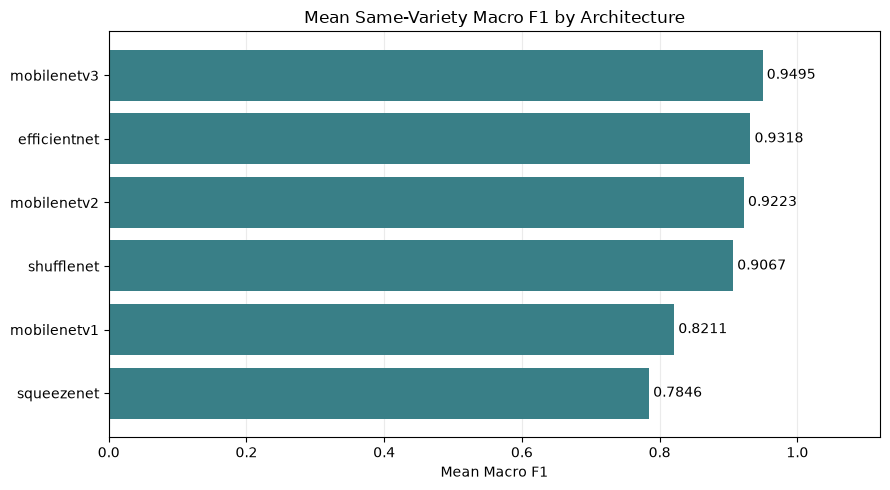

Mean Macro F1 by architecture (all same-variety runs):


,mean_f1,n
model,,
squeezenet,0.7846,10
mobilenetv1,0.8211,10
shufflenet,0.9067,10
mobilenetv2,0.9223,10
efficientnet,0.9318,10
mobilenetv3,0.9495,10



Mean of architecture means: 0.8860


In [8]:
same_variety = df.loc[df["test_variety"].eq("same")].copy()

architecture_mean_f1 = (
    same_variety.groupby("model")["macro_avg__f1-score"]
    .agg(mean_f1="mean", n="size")
    .sort_values("mean_f1")
)

top_mean_f1 = architecture_mean_f1["mean_f1"].mean()

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(architecture_mean_f1.index, architecture_mean_f1["mean_f1"], color="#397f87")
for bar, (mean_f1, count) in zip(bars, architecture_mean_f1[["mean_f1", "n"]].itertuples(index=False, name=None)):
    ax.text(mean_f1 + 0.006, bar.get_y() + bar.get_height() / 2, f"{mean_f1:.4f}", va="center")

ax.set(title="Mean Same-Variety Macro F1 by Architecture", xlabel="Mean Macro F1", xlim=(0, 1.12))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print("Mean Macro F1 by architecture (all same-variety runs):")
display(architecture_mean_f1)
print(f"\nMean of architecture means: {top_mean_f1:.4f}")


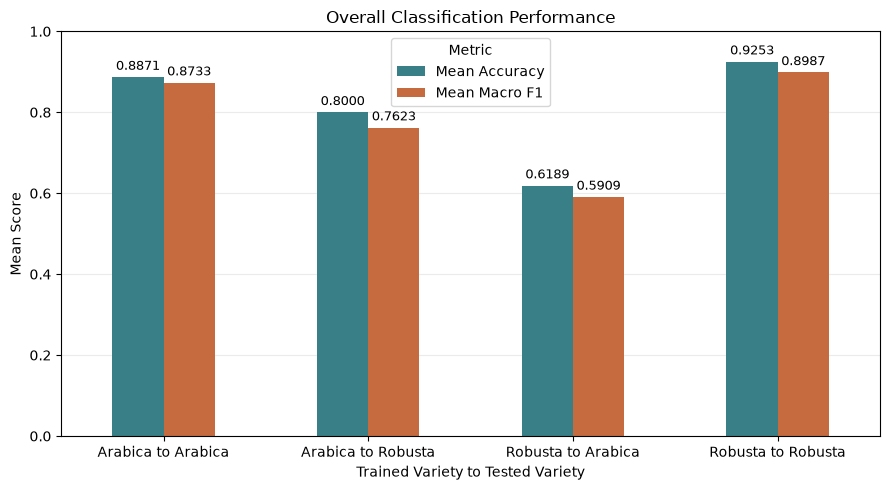

,Mean Accuracy,Mean Macro F1
direction,,
Arabica to Arabica,0.8871,0.8733
Arabica to Robusta,0.8000,0.7623
Robusta to Arabica,0.6189,0.5909
Robusta to Robusta,0.9253,0.8987


In [4]:
variety_opposite = {"arabica": "robusta", "robusta": "arabica"}
variety_results = df.copy()
variety_results["tested_variety"] = variety_results.apply(
    lambda row: (
        row["train_variety"]
        if row["test_variety"] == "same"
        else variety_opposite[row["train_variety"]]
    ),
    axis=1,
)
variety_results["direction"] = (
    variety_results["train_variety"].str.title()
    + " to "
    + variety_results["tested_variety"].str.title()
)

direction_means = (
    variety_results.groupby("direction")[["accuracy", "macro_avg__f1-score"]]
    .mean()
    .rename(columns={"accuracy": "Mean Accuracy", "macro_avg__f1-score": "Mean Macro F1"})
    .sort_index()
)

import matplotlib.pyplot as plt

ax = direction_means.plot(kind="bar", figsize=(9, 5), color=["#397f87", "#c56b3f"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3, fontsize=9)
ax.set(
    title="Overall Classification Performance",
    xlabel="Trained Variety to Tested Variety",
    ylabel="Mean Score",
    ylim=(0, 1),
)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Metric")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

display(direction_means)


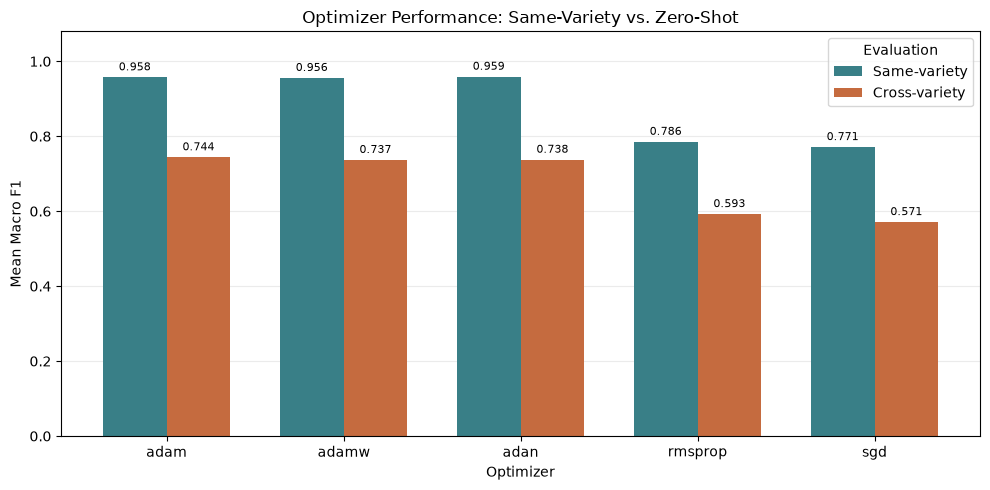

test_variety,Cross-variety,Same-variety
optimizer,,
adam,0.7443,0.9577
adamw,0.7371,0.9560
adan,0.7377,0.9593
rmsprop,0.5927,0.7856
sgd,0.5713,0.7715


In [18]:
optimizer_order = ["adam", "adamw", "adan", "rmsprop", "sgd"]
optimizer_f1_means = (
    df.groupby(["optimizer", "test_variety"])["macro_avg__f1-score"]
    .mean()
    .unstack("test_variety")
    .reindex(optimizer_order)
    .rename(columns={"same": "Same-variety", "other": "Cross-variety"})
)

import matplotlib.pyplot as plt
import numpy as np

positions = np.arange(len(optimizer_f1_means))
bar_width = 0.36
fig, ax = plt.subplots(figsize=(10, 5))
same_bars = ax.bar(
    positions - bar_width / 2,
    optimizer_f1_means["Same-variety"],
    bar_width,
    label="Same-variety",
    color="#397f87",
)
cross_bars = ax.bar(
    positions + bar_width / 2,
    optimizer_f1_means["Cross-variety"],
    bar_width,
    label="Cross-variety",
    color="#c56b3f",
)
ax.bar_label(same_bars, fmt="%.3f", padding=3, fontsize=8)
ax.bar_label(cross_bars, fmt="%.3f", padding=3, fontsize=8)
ax.set(
    title="Optimizer Performance: Same-Variety vs. Zero-Shot",
    xlabel="Optimizer",
    ylabel="Mean Macro F1",
    ylim=(0, 1.08),
    xticks=positions,
    xticklabels=optimizer_f1_means.index,
)
ax.legend(title="Evaluation")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

display(optimizer_f1_means)


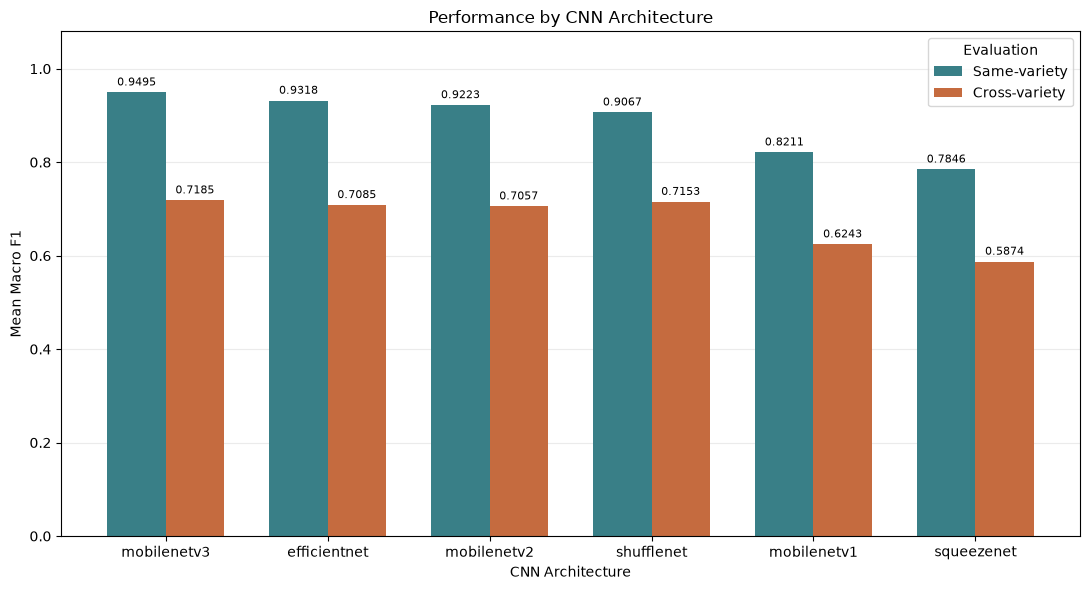

test_variety,Cross-variety,Same-variety
model,,
mobilenetv3,0.7185,0.9495
efficientnet,0.7085,0.9318
mobilenetv2,0.7057,0.9223
shufflenet,0.7153,0.9067
mobilenetv1,0.6243,0.8211
squeezenet,0.5874,0.7846


In [20]:
architecture_f1_means = (
    df.groupby(["model", "test_variety"])["macro_avg__f1-score"]
    .mean()
    .unstack("test_variety")
    .rename(columns={"same": "Same-variety", "other": "Cross-variety"})
    .sort_values("Same-variety", ascending=False)
)

import matplotlib.pyplot as plt
import numpy as np

positions = np.arange(len(architecture_f1_means))
bar_width = 0.36
fig, ax = plt.subplots(figsize=(11, 6))
same_bars = ax.bar(
    positions - bar_width / 2,
    architecture_f1_means["Same-variety"],
    bar_width,
    label="Same-variety",
    color="#397f87",
)
cross_bars = ax.bar(
    positions + bar_width / 2,
    architecture_f1_means["Cross-variety"],
    bar_width,
    label="Cross-variety",
    color="#c56b3f",
)
ax.bar_label(same_bars, fmt="%.4f", padding=3, fontsize=8)
ax.bar_label(cross_bars, fmt="%.4f", padding=3, fontsize=8)
ax.set(
    title="Performance by CNN Architecture",
    xlabel="CNN Architecture",
    ylabel="Mean Macro F1",
    ylim=(0, 1.08),
    xticks=positions,
    xticklabels=architecture_f1_means.index,
)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Evaluation")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

display(architecture_f1_means)


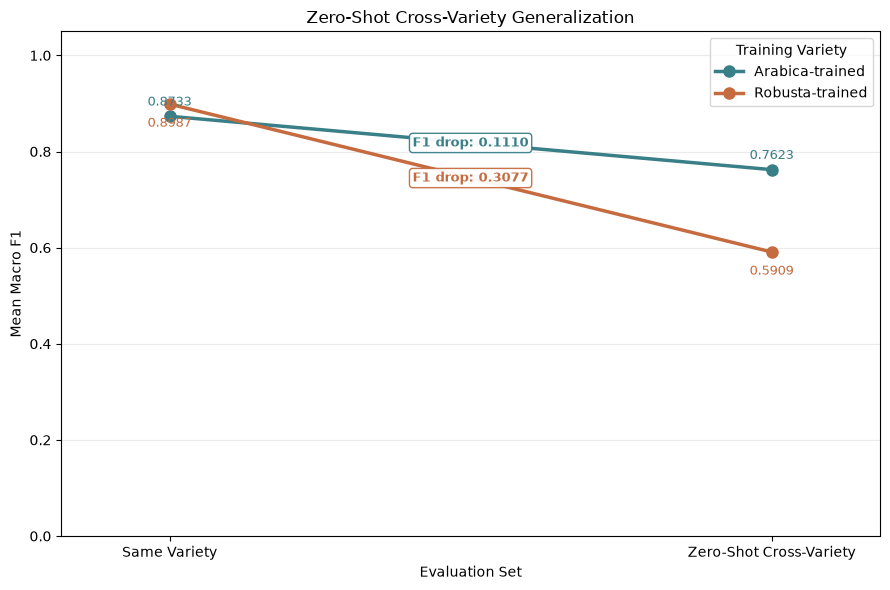

test_variety,Zero-shot Macro F1,Same-variety Macro F1,F1 drop
train_variety,,,
Arabica-trained,0.7623,0.8733,0.1110
Robusta-trained,0.5909,0.8987,0.3077


In [26]:
cross_variety_summary = (
    df.groupby(["train_variety", "test_variety"])["macro_avg__f1-score"]
    .mean()
    .unstack("test_variety")
    .reindex(["arabica", "robusta"])
)

fig, ax = plt.subplots(figsize=(9, 6))
evaluation_positions = np.arange(2)
evaluation_labels = ["Same Variety", "Zero-Shot Cross-Variety"]
line_colors = {"arabica": "#397f87", "robusta": "#c56b3f"}
label_offsets = {"arabica": 10, "robusta": -14}

for train_variety, scores in cross_variety_summary.iterrows():
    values = [scores["same"], scores["other"]]
    color = line_colors[train_variety]
    ax.plot(
        evaluation_positions,
        values,
        marker="o",
        linewidth=2.5,
        markersize=8,
        color=color,
        label=f"{train_variety.title()}-trained",
    )
    for x_position, score in zip(evaluation_positions, values):
        ax.annotate(
            f"{score:.4f}",
            (x_position, score),
            xytext=(0, label_offsets[train_variety]),
            textcoords="offset points",
            ha="center",
            va="center",
            color=color,
            fontsize=9,
        )

    f1_drop = scores["same"] - scores["other"]
    ax.annotate(
        f"F1 drop: {f1_drop:.4f}",
        (0.5, np.mean(values)),
        ha="center",
        va="center",
        color=color,
        fontsize=9,
        fontweight="bold",
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": color, "alpha": 0.95},
    )

cross_variety_summary["f1_drop"] = cross_variety_summary["same"] - cross_variety_summary["other"]
ax.set(
    title="Zero-Shot Cross-Variety Generalization",
    xlabel="Evaluation Set",
    ylabel="Mean Macro F1",
    xticks=evaluation_positions,
    xticklabels=evaluation_labels,
    xlim=(-0.18, 1.18),
    ylim=(0, 1.05),
)
ax.legend(title="Training Variety")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

display(
    cross_variety_summary.rename(
        index={"arabica": "Arabica-trained", "robusta": "Robusta-trained"},
        columns={"same": "Same-variety Macro F1", "other": "Zero-shot Macro F1", "f1_drop": "F1 drop"},
    )
)


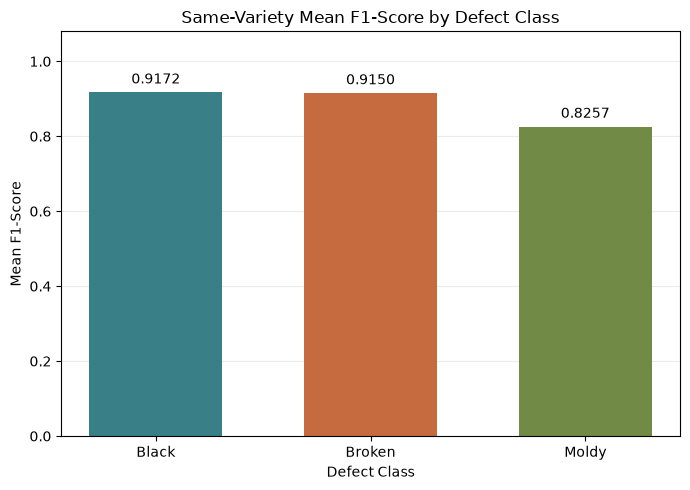

,Same-Variety Mean F1-Score
Black,0.9172
Broken,0.9150
Moldy,0.8257


In [29]:
same_variety_results = df.loc[df["test_variety"].eq("same")]
class_f1_columns = ["black__f1-score", "broken__f1-score", "moldy__f1-score"]
class_f1_means = (
    same_variety_results[class_f1_columns]
    .mean()
    .rename({
        "black__f1-score": "Black",
        "broken__f1-score": "Broken",
        "moldy__f1-score": "Moldy",
    })
)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    class_f1_means.index,
    class_f1_means.values,
    color=["#397f87", "#c56b3f", "#718a45"],
    width=0.62,
)
ax.bar_label(bars, labels=[f"{score:.4f}" for score in class_f1_means.values], padding=4)
ax.set(
    title="Same-Variety Mean F1-Score by Defect Class",
    xlabel="Defect Class",
    ylabel="Mean F1-Score",
    ylim=(0, 1.08),
)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

display(class_f1_means.to_frame("Same-Variety Mean F1-Score").round(4))


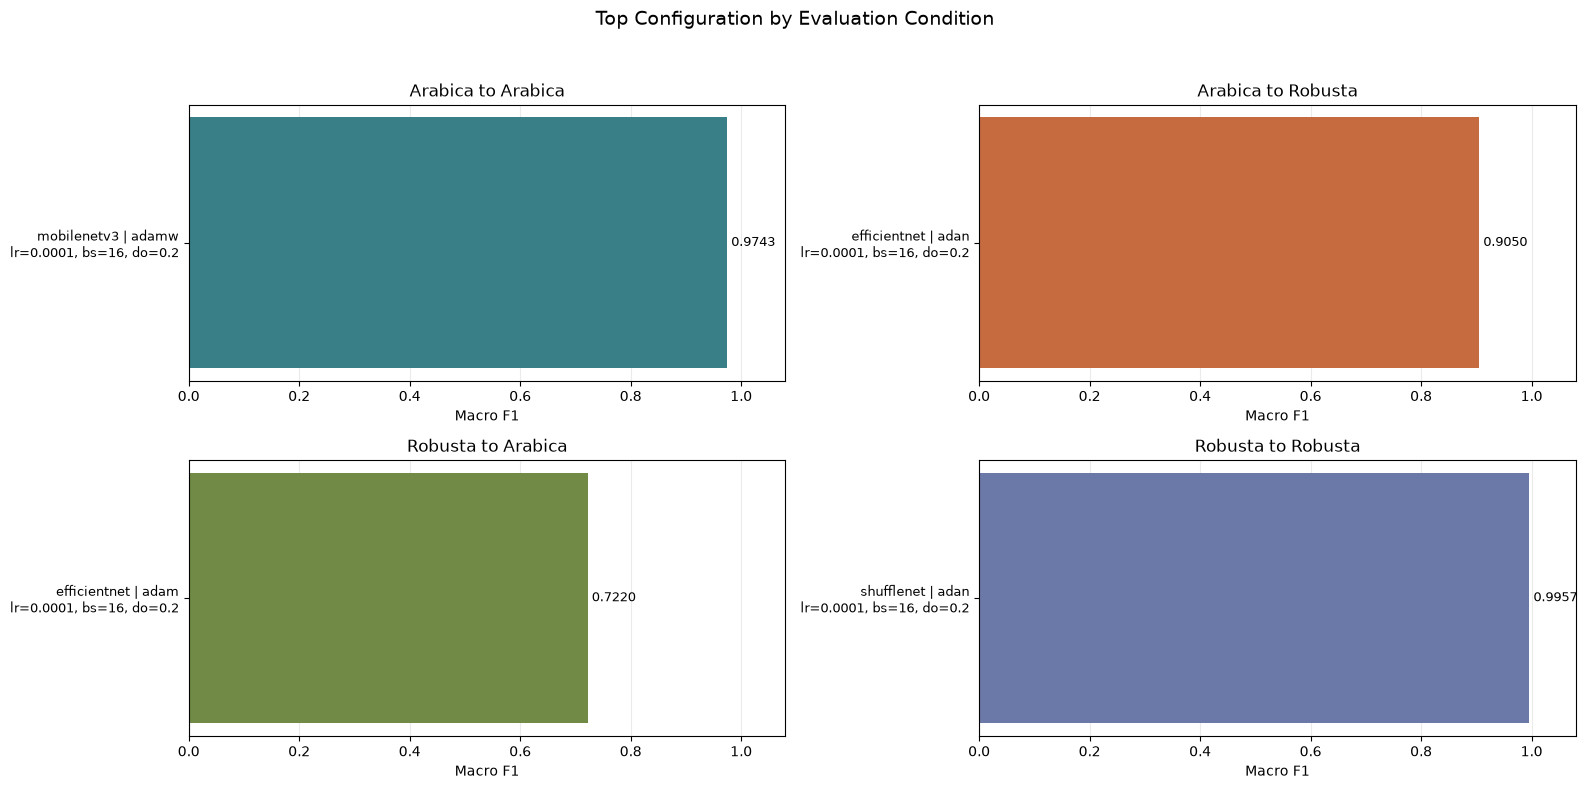

,evaluation_condition,model,optimizer,lr,batch_size,dropout,macro_avg__f1-score
32,Arabica to Arabica,mobilenetv3,adamw,0.0001,16,0.2000,0.9743
5,Arabica to Robusta,efficientnet,adan,0.0001,16,0.2000,0.9050
61,Robusta to Arabica,efficientnet,adam,0.0001,16,0.2000,0.7220
104,Robusta to Robusta,shufflenet,adan,0.0001,16,0.2000,0.9957


In [34]:
opposite_variety = {"arabica": "robusta", "robusta": "arabica"}
top_config_results = df.copy()
top_config_results["tested_variety"] = np.where(
    top_config_results["test_variety"].eq("same"),
    top_config_results["train_variety"],
    top_config_results["train_variety"].map(opposite_variety),
)
top_config_results["evaluation_condition"] = (
    top_config_results["train_variety"].str.title()
    + " to "
    + top_config_results["tested_variety"].str.title()
)
top_config_results["config_label"] = top_config_results.apply(
    lambda row: (
        f"{row['model']} | {row['optimizer']}\n"
        f"lr={row['lr']:g}, bs={row['batch_size']}, do={row['dropout']:g}"
    ),
    axis=1,
)

evaluation_condition_order = [
    "Arabica to Arabica",
    "Arabica to Robusta",
    "Robusta to Arabica",
    "Robusta to Robusta",
]
top_config_by_condition = (
    top_config_results.sort_values("macro_avg__f1-score", ascending=False)
    .groupby("evaluation_condition", sort=False)
    .head(1)
    .copy()
)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
condition_colors = ["#397f87", "#c56b3f", "#718a45", "#6b79a8"]
for ax, condition, color in zip(axes.flat, evaluation_condition_order, condition_colors):
    condition_top = top_config_by_condition.loc[
        top_config_by_condition["evaluation_condition"].eq(condition)
    ]
    bars = ax.barh(
        condition_top["config_label"],
        condition_top["macro_avg__f1-score"],
        color=color,
    )
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
    ax.set(title=condition, xlabel="Macro F1", xlim=(0, 1.08))
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle("Top Configuration by Evaluation Condition", fontsize=14)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

display(
    top_config_by_condition[
        ["evaluation_condition", "model", "optimizer", "lr", "batch_size", "dropout", "macro_avg__f1-score"]
    ].sort_values("evaluation_condition")
)


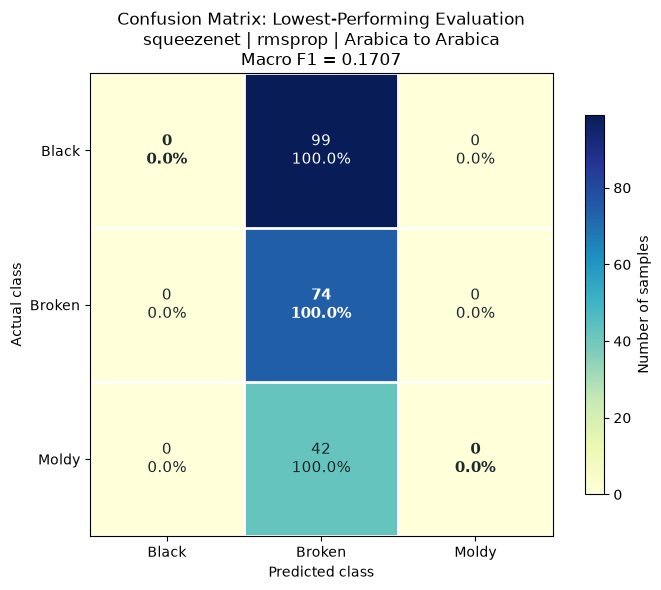

Lowest Macro F1: 0.1707 | Model: squeezenet | Optimizer: rmsprop | Run: fixed_NORLR_arabica_squeezenet_rmsprop_lr1e-4_bs16_do0.2


In [35]:
import ast

worst_result = df.loc[df["macro_avg__f1-score"].idxmin()]
worst_matrix = np.asarray(ast.literal_eval(worst_result["confusion_matrix"]), dtype=int)
row_totals = worst_matrix.sum(axis=1, keepdims=True)
row_percentages = np.divide(
    worst_matrix,
    row_totals,
    out=np.zeros_like(worst_matrix, dtype=float),
    where=row_totals != 0,
) * 100
class_labels = ["Black", "Broken", "Moldy"]

fig, ax = plt.subplots(figsize=(7.5, 6))
image = ax.imshow(worst_matrix, cmap="YlGnBu")
colorbar = fig.colorbar(image, ax=ax, shrink=0.82)
colorbar.set_label("Number of samples")

ax.set_xticks(np.arange(len(class_labels)), labels=class_labels)
ax.set_yticks(np.arange(len(class_labels)), labels=class_labels)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title(
    "Confusion Matrix: Lowest-Performing Evaluation\n"
    f"{worst_result['model']} | {worst_result['optimizer']} | "
    f"{worst_result['train_variety'].title()} to "
    f"{worst_result['train_variety'].title() if worst_result['test_variety'] == 'same' else opposite_variety[worst_result['train_variety']] .title()}\n"
    f"Macro F1 = {worst_result['macro_avg__f1-score']:.4f}"
)

threshold = worst_matrix.max() / 2 if worst_matrix.size else 0
for row_index in range(worst_matrix.shape[0]):
    for column_index in range(worst_matrix.shape[1]):
        count = worst_matrix[row_index, column_index]
        percentage = row_percentages[row_index, column_index]
        ax.text(
            column_index,
            row_index,
            f"{count}\n{percentage:.1f}%",
            ha="center",
            va="center",
            color="white" if count > threshold else "#1d292b",
            fontsize=11,
            fontweight="bold" if row_index == column_index else "normal",
        )

ax.set_xticks(np.arange(-0.5, len(class_labels), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(class_labels), 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)
plt.tight_layout()
plt.show()

print(
    f"Lowest Macro F1: {worst_result['macro_avg__f1-score']:.4f} | "
    f"Model: {worst_result['model']} | Optimizer: {worst_result['optimizer']} | "
    f"Run: {worst_result['run_name']}"
)


## Training-curve diagnosis from checkpoint JSON

The next cell reads each `linuxcheckpoints/**/results.json` file and summarizes the stored training and validation history. It ranks late validation-loss increases as possible overfitting signals, and surfaces runs with weak training accuracy as possible underfitting candidates. The plotted run is the one with the largest validation-loss rise after its best-validation-loss epoch.

Interpret the signals together, not as automatic labels:

- **Possible overfitting:** after the best validation-loss epoch, training loss continues to fall while validation loss rises over several epochs.
- **Possible underfitting:** training performance itself remains weak (high training loss and low training accuracy), as well as validation performance.
- **Better fit:** both losses fall and then level off, with validation metrics remaining stable.

Important for these runs: the training loop logs training metrics in training mode and applies randomized train transforms, while validation runs in evaluation mode on deterministic transforms. This can make training loss higher than validation loss even without a bug; compare the curve trends and final held-out test metrics, not just the absolute train-validation gap. Validation is used for checkpoint selection, so reserve test metrics for final reporting.

The current simple late-divergence screen flags 38 of 60 runs, but that is a review queue, not a claim that 38 models are definitively overfit. The lowest-training-accuracy table also points to weakly learning configurations, including some SGD runs; poor fit and late validation deterioration can occur in the same run.


Found 60 results.json files; 60 contain usable epoch histories.

Possible late overfit trend (at least 3 epochs after best, train loss falls, final validation loss rises): 38 of 60 runs.
This is a screening signal, not a definitive label; review the curves below.

Largest absolute train-validation loss gaps at the best-validation-loss epoch:


,run_name,best_epoch,train_loss_at_best,val_loss_at_best,loss_gap_at_best,train_acc_at_best,val_acc_at_best,accuracy_gap_at_best
9,fixed_NORLR_arabica_mobilenetv1_sgd_lr1e-4_bs1...,85,3.615037,1.931135,-1.683902,0.393638,0.560185,-0.166547
39,fixed_NORLR_robusta_mobilenetv1_sgd_lr1e-4_bs1...,87,2.892266,1.716478,-1.175788,0.449153,0.610169,-0.161017
37,fixed_NORLR_robusta_mobilenetv1_adan_lr1e-4_bs...,58,0.405707,0.104420,-0.301288,0.909201,0.960452,-0.051251
8,fixed_NORLR_arabica_mobilenetv1_rmsprop_lr1e-4...,86,0.926805,0.625986,-0.300820,0.581511,0.717593,-0.136082
5,fixed_NORLR_arabica_mobilenetv1_adam_lr1e-4_bs...,78,0.461189,0.179579,-0.281610,0.841948,0.921296,-0.079348
36,fixed_NORLR_robusta_mobilenetv1_adamw_lr1e-4_b...,27,0.374784,0.094639,-0.280145,0.883777,0.977401,-0.093624
35,fixed_NORLR_robusta_mobilenetv1_adam_lr1e-4_bs...,86,0.356222,0.103955,-0.252267,0.894673,0.954802,-0.060129
18,fixed_NORLR_arabica_mobilenetv3_rmsprop_lr1e-4...,40,0.399942,0.160170,-0.239771,0.870775,0.935185,-0.064410
7,fixed_NORLR_arabica_mobilenetv1_adan_lr1e-4_bs...,71,0.372555,0.141081,-0.231475,0.879722,0.953704,-0.073982
38,fixed_NORLR_robusta_mobilenetv1_rmsprop_lr1e-4...,99,0.717691,0.503176,-0.214515,0.757869,0.836158,-0.078289



Runs with the largest final validation-loss rise after their best epoch:


,run_name,best_epoch,epochs_after_best,final_train_loss_change,final_val_loss_change,final_train_acc_change,final_val_acc_change
9,fixed_NORLR_arabica_mobilenetv1_sgd_lr1e-4_bs1...,85,15,-0.327745,0.414149,0.036779,-0.032407
7,fixed_NORLR_arabica_mobilenetv1_adan_lr1e-4_bs...,71,29,-0.129887,0.276645,0.039761,-0.009259
35,fixed_NORLR_robusta_mobilenetv1_adam_lr1e-4_bs...,86,14,-0.114682,0.253112,0.035109,-0.011299
16,fixed_NORLR_arabica_mobilenetv3_adamw_lr1e-4_b...,21,79,-0.139749,0.251874,0.045726,-0.041667
13,fixed_NORLR_arabica_mobilenetv2_rmsprop_lr1e-4...,88,12,-0.014487,0.217395,0.009940,-0.074074
8,fixed_NORLR_arabica_mobilenetv1_rmsprop_lr1e-4...,86,14,-0.073204,0.216997,0.038767,-0.106481
15,fixed_NORLR_arabica_mobilenetv3_adam_lr1e-4_bs...,15,85,-0.159754,0.215480,0.048708,-0.023148
37,fixed_NORLR_robusta_mobilenetv1_adan_lr1e-4_bs...,58,42,-0.159658,0.214845,0.032688,-0.028249
56,fixed_NORLR_robusta_squeezenet_adamw_lr1e-4_bs...,71,29,-0.121254,0.212316,0.010896,-0.005650
39,fixed_NORLR_robusta_mobilenetv1_sgd_lr1e-4_bs1...,87,13,-0.245956,0.201892,0.039952,0.000000



Lowest training accuracy at the best-validation-loss epoch (possible underfitting candidates):


,run_name,best_epoch,train_loss_at_best,train_acc_at_best,val_loss_at_best,val_acc_at_best
9,fixed_NORLR_arabica_mobilenetv1_sgd_lr1e-4_bs1...,85,3.615037,0.393638,1.931135,0.560185
58,fixed_NORLR_robusta_squeezenet_rmsprop_lr1e-4_...,24,1.098789,0.429782,1.084175,0.435028
39,fixed_NORLR_robusta_mobilenetv1_sgd_lr1e-4_bs1...,87,2.892266,0.449153,1.716478,0.610169
28,fixed_NORLR_arabica_squeezenet_rmsprop_lr1e-4_...,42,1.098612,0.462227,1.098342,0.347222
8,fixed_NORLR_arabica_mobilenetv1_rmsprop_lr1e-4...,86,0.926805,0.581511,0.625986,0.717593
24,fixed_NORLR_arabica_shufflenet_sgd_lr1e-4_bs16...,100,1.075601,0.698807,1.066833,0.768519
14,fixed_NORLR_arabica_mobilenetv2_sgd_lr1e-4_bs1...,98,0.711439,0.735586,0.565959,0.773148
54,fixed_NORLR_robusta_shufflenet_sgd_lr1e-4_bs16...,96,1.071917,0.745763,1.045302,0.796610
38,fixed_NORLR_robusta_mobilenetv1_rmsprop_lr1e-4...,99,0.717691,0.757869,0.503176,0.836158
19,fixed_NORLR_arabica_mobilenetv3_sgd_lr1e-4_bs1...,100,0.593464,0.758449,0.454202,0.810185


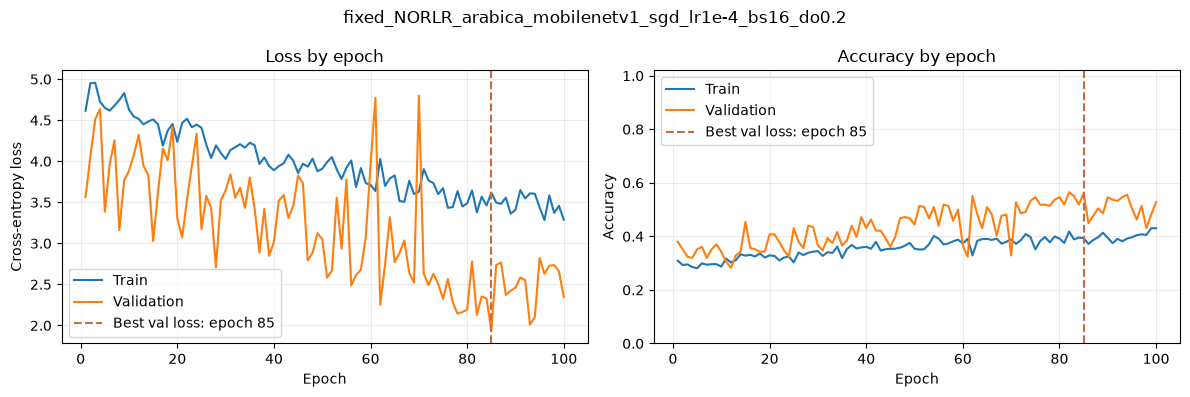

In [3]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

checkpoint_dir = Path("linuxcheckpoints")
if not checkpoint_dir.is_dir():
    checkpoint_dir = Path("/mnt/HDData/codes/school/prototype/linuxcheckpoints")

history_rows = []
run_summaries = []
json_paths = sorted(checkpoint_dir.rglob("results.json"))

for json_path in json_paths:
    with json_path.open(encoding="utf-8") as file:
        run = json.load(file)

    history = run.get("history", [])
    if not history:
        continue

    for epoch_result in history:
        history_rows.append({
            "run_name": run.get("run_name", json_path.parent.name),
            "variety": run.get("variety"),
            "model": run.get("model"),
            "optimizer": run.get("optimizer"),
            "lr": run.get("lr"),
            "batch_size": run.get("batch_size"),
            "dropout": run.get("dropout"),
            **epoch_result,
        })

    run_history = pd.DataFrame(history).sort_values("epoch")
    required_metrics = {"tr_loss", "tr_acc", "vl_loss", "vl_acc"}
    if not required_metrics.issubset(run_history.columns):
        continue

    best_row = run_history.loc[run_history["vl_loss"].idxmin()]
    after_best = run_history.loc[run_history["epoch"] > best_row["epoch"]]
    last_row = run_history.iloc[-1]

    run_summaries.append({
        "run_name": run.get("run_name", json_path.parent.name),
        "variety": run.get("variety"),
        "model": run.get("model"),
        "optimizer": run.get("optimizer"),
        "best_epoch": int(best_row["epoch"]),
        "epochs_after_best": len(after_best),
        "train_loss_at_best": best_row["tr_loss"],
        "val_loss_at_best": best_row["vl_loss"],
        "loss_gap_at_best": best_row["vl_loss"] - best_row["tr_loss"],
        "train_acc_at_best": best_row["tr_acc"],
        "val_acc_at_best": best_row["vl_acc"],
        "accuracy_gap_at_best": best_row["tr_acc"] - best_row["vl_acc"],
        "final_train_loss_change": last_row["tr_loss"] - best_row["tr_loss"],
        "final_val_loss_change": last_row["vl_loss"] - best_row["vl_loss"],
        "final_train_acc_change": last_row["tr_acc"] - best_row["tr_acc"],
        "final_val_acc_change": last_row["vl_acc"] - best_row["vl_acc"],
    })

history_df = pd.DataFrame(history_rows)
overfit_summary = pd.DataFrame(run_summaries)
print(f"Found {len(json_paths)} results.json files; {len(overfit_summary)} contain usable epoch histories.")
if overfit_summary.empty:
    raise ValueError(f"No usable train/validation histories found under {checkpoint_dir}")

overfit_summary["absolute_loss_gap_at_best"] = overfit_summary["loss_gap_at_best"].abs()
overfit_trend = (
    (overfit_summary["epochs_after_best"] >= 3)
    & (overfit_summary["final_train_loss_change"] < 0)
    & (overfit_summary["final_val_loss_change"] > 0)
)
print(
    f"\nPossible late overfit trend (at least 3 epochs after best, train loss falls, "
    f"final validation loss rises): {overfit_trend.sum()} of {len(overfit_summary)} runs."
)
print("This is a screening signal, not a definitive label; review the curves below.")

print("\nLargest absolute train-validation loss gaps at the best-validation-loss epoch:")
display(
    overfit_summary.sort_values("absolute_loss_gap_at_best", ascending=False)[
        ["run_name", "best_epoch", "train_loss_at_best", "val_loss_at_best", "loss_gap_at_best",
         "train_acc_at_best", "val_acc_at_best", "accuracy_gap_at_best"]
    ].head(15)
)

print("\nRuns with the largest final validation-loss rise after their best epoch:")
display(
    overfit_summary.sort_values("final_val_loss_change", ascending=False)[
        ["run_name", "best_epoch", "epochs_after_best", "final_train_loss_change", "final_val_loss_change",
         "final_train_acc_change", "final_val_acc_change"]
    ].head(15)
)

print("\nLowest training accuracy at the best-validation-loss epoch (possible underfitting candidates):")
display(
    overfit_summary.sort_values("train_acc_at_best")[[
        "run_name", "best_epoch", "train_loss_at_best", "train_acc_at_best", "val_loss_at_best", "val_acc_at_best"
    ]].head(15)
)


def plot_run_history(run_name):
    run_history = history_df.loc[history_df["run_name"].eq(run_name)].sort_values("epoch")
    if run_history.empty:
        raise ValueError(f"No epoch history found for run: {run_name}")

    best_position = run_history["vl_loss"].idxmin()
    best_epoch = int(run_history.loc[best_position, "epoch"])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(run_history["epoch"], run_history["tr_loss"], label="Train")
    axes[0].plot(run_history["epoch"], run_history["vl_loss"], label="Validation")
    axes[0].axvline(best_epoch, color="#c56b3f", linestyle="--", label=f"Best val loss: epoch {best_epoch}")
    axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(run_history["epoch"], run_history["tr_acc"], label="Train")
    axes[1].plot(run_history["epoch"], run_history["vl_acc"], label="Validation")
    axes[1].axvline(best_epoch, color="#c56b3f", linestyle="--", label=f"Best val loss: epoch {best_epoch}")
    axes[1].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.02))
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    fig.suptitle(run_name)
    plt.tight_layout()
    plt.show()


# Plot the run with the largest post-best validation-loss increase.
example_run = overfit_summary.sort_values("final_val_loss_change", ascending=False).iloc[0]["run_name"]
plot_run_history(example_run)